# Hough Transform — Experimental Evaluation

## Objectives

Evaluate the performance of three Hough Transform configurations:
- Coarse Hough Transform
- Fine Hough Transform
- Multi-scale Hough Transform

Evaluation metrics:
- Angular error
- Peak-to-background ratio
- Execution time

Experiments will analyze the effects of Δθ and Δρ.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Working directory:", Path.cwd())

Python: 3.14.3 (main, Mar 10 2026, 18:14:48) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.4
Working directory: c:\Users\PC\Image-Process-and-Computer-Vision\notebooks


In [2]:
import sys
from pathlib import Path

project_root = Path.cwd()

if not (project_root / "hough_submission.py").exists():
    project_root = project_root.parent

assert (project_root / "hough_submission.py").exists(), \
    "Cannot find hough_submission.py"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from hough_submission import (
    hough_accumulate,
    find_peaks,
    hough_multiscale
)

print("Hough functions imported successfully!")

Hough functions imported successfully!


## 2. Synthetic Dataset and Ground Truth

This experiment uses a synthetic binary edge image containing a single straight line.

The line parameters are known in advance, allowing us to evaluate the angular accuracy of the Hough Transform.

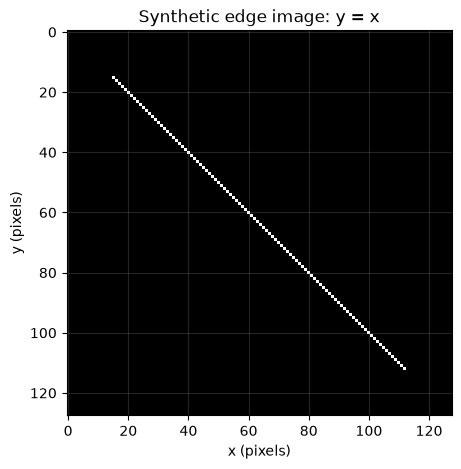

Image shape: (128, 128)
Number of edge pixels: 98
Ground-truth theta: 135.0 degrees
Ground-truth rho: 0.0 pixels


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Create a 128x128 binary edge image
H, W = 128, 128
edges = np.zeros((H, W), dtype=np.uint8)

# Ground-truth line: y = x
for x in range(15, 113):
    y = x
    edges[y, x] = 255

# Ground-truth normal angle for y = x
theta_true_deg = 135.0
rho_true = 0.0

plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap="gray", vmin=0, vmax=255)
plt.title("Synthetic edge image: y = x")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.grid(alpha=0.2)
plt.show()

print("Image shape:", edges.shape)
print("Number of edge pixels:", np.count_nonzero(edges))
print("Ground-truth theta:", theta_true_deg, "degrees")
print("Ground-truth rho:", rho_true, "pixels")

## 3. Coarse Hough Transform

This experiment evaluates whether the existing Hough implementation can recover a line with known parameters using coarse angular and distance resolutions.

In [4]:
diag = np.hypot(H, W)

delta_theta_deg = 2.0
delta_rho = 2.0

n_theta = int(np.ceil(180 / delta_theta_deg))
n_rho = int(np.ceil(2 * diag / delta_rho)) + 1

A, thetas, rhos = hough_accumulate(
    edges=edges,
    theta_range=(0.0, np.pi),
    rho_range=(-diag, diag),
    n_theta=n_theta,
    n_rho=n_rho
)

peaks = find_peaks(
    A,
    n_peaks=1,
    nms_radius=3,
    smooth_sigma=1.0,
    thetas=thetas,
    rhos=rhos
)

print("Accumulator shape:", A.shape)
print("Detected peaks:", peaks)

if peaks:
    rho_pred, theta_pred, votes = peaks[0]
    theta_pred_deg = np.rad2deg(theta_pred)

    angular_error = abs(theta_pred_deg - theta_true_deg) % 180
    angular_error = min(angular_error, 180 - angular_error)

    print("Predicted theta:", theta_pred_deg)
    print("Angular error:", angular_error, "degrees")
    print("Votes:", votes)

Accumulator shape: (183, 90)
Detected peaks: [(np.float64(1.9892234723489821), np.float64(2.3387411976724017), 72)]
Predicted theta: 134.0
Angular error: 1.0 degrees
Votes: 72


## 4. Multi-scale Hough Transform

This experiment evaluates whether local refinement improves line detection accuracy compared with the coarse Hough Transform.

The same synthetic edge image is used to ensure a consistent comparison.

In [5]:
import time

start = time.perf_counter()

refined_lines = hough_multiscale(
    edges=edges,
    n_levels=2,
    refine_factor=8,
    n_peaks=1,
    d_theta_coarse_deg=2.0,
    d_rho_coarse=2.0,
    nms_radius=3,
    smooth_sigma=1.0
)

elapsed_ms = (time.perf_counter() - start) * 1000

print("Refined lines:", refined_lines)
print("Runtime:", elapsed_ms, "ms")

if refined_lines:
    rho_multi, theta_multi = refined_lines[0]
    theta_multi_deg = np.rad2deg(theta_multi)

    difference = abs(theta_multi_deg - theta_true_deg) % 180
    angular_error_multi = min(difference, 180 - difference)

    print("Predicted theta:", theta_multi_deg)
    print("Angular error:", angular_error_multi, "degrees")
    print("Predicted rho:", rho_multi)

Refined lines: [(np.float64(0.05445468884008431), np.float64(2.356194490192345))]
Runtime: 52.086700015934184 ms
Predicted theta: 135.0
Angular error: 0.0 degrees
Predicted rho: 0.05445468884008431


## Fine Hough Transform

This experiment uses a finer parameter resolution to compare angular accuracy with Coarse and Multi-scale Hough Transform.

In [6]:
# Fine Hough experiment
delta_theta_fine = 0.25
delta_rho_fine = 0.5

n_theta_fine = int(np.ceil(180 / delta_theta_fine))
n_rho_fine = int(np.ceil(2 * diag / delta_rho_fine)) + 1

A_fine, thetas_fine, rhos_fine = hough_accumulate(
    edges=edges,
    theta_range=(0.0, np.pi),
    rho_range=(-diag, diag),
    n_theta=n_theta_fine,
    n_rho=n_rho_fine
)

peaks_fine = find_peaks(
    A_fine,
    n_peaks=1,
    nms_radius=3,
    smooth_sigma=1.0,
    thetas=thetas_fine,
    rhos=rhos_fine
)

print("Fine Hough peaks:", peaks_fine)

if peaks_fine:
    rho_fine, theta_fine, votes_fine = peaks_fine[0]

    theta_fine_deg = np.rad2deg(theta_fine)

    diff = abs(theta_fine_deg - theta_true_deg) % 180
    error_fine = min(diff, 180 - diff)

    print("Predicted theta:", theta_fine_deg)
    print("Angular error:", error_fine, "degrees")
    print("Predicted rho:", rho_fine)

Fine Hough peaks: [(np.float64(-0.24968184273620864), np.float64(2.360557813322331), 66)]
Predicted theta: 135.25
Angular error: 0.25 degrees
Predicted rho: -0.24968184273620864


## 5. Runtime Benchmark

This experiment compares the execution time of Coarse, Fine, and Multi-scale Hough Transform using the same synthetic edge image.

Each method is executed five times. The median execution time is used to reduce measurement variability.

In [7]:
import time
import numpy as np

def benchmark(func, repeats=5):
    times = []

    # Warm-up
    func()

    for _ in range(repeats):
        start = time.perf_counter()
        func()
        elapsed = (time.perf_counter() - start) * 1000
        times.append(elapsed)

    return np.median(times), times

In [8]:
def run_coarse():
    A, thetas, rhos = hough_accumulate(
        edges, (0.0, np.pi), (-diag, diag),
        n_theta, n_rho
    )
    return find_peaks(
        A, n_peaks=1, nms_radius=3,
        smooth_sigma=1.0,
        thetas=thetas, rhos=rhos
    )

def run_fine():
    A, thetas, rhos = hough_accumulate(
        edges, (0.0, np.pi), (-diag, diag),
        n_theta_fine, n_rho_fine
    )
    return find_peaks(
        A, n_peaks=1, nms_radius=3,
        smooth_sigma=1.0,
        thetas=thetas, rhos=rhos
    )

def run_multiscale():
    return hough_multiscale(
        edges=edges,
        n_levels=2,
        refine_factor=8,
        n_peaks=1,
        d_theta_coarse_deg=2.0,
        d_rho_coarse=2.0,
        nms_radius=3,
        smooth_sigma=1.0
    )

In [9]:
coarse_ms, coarse_times = benchmark(run_coarse)
fine_ms, fine_times = benchmark(run_fine)
multi_ms, multi_times = benchmark(run_multiscale)

print(f"Coarse Hough:      {coarse_ms:.2f} ms")
print(f"Fine Hough:        {fine_ms:.2f} ms")
print(f"Multi-scale Hough: {multi_ms:.2f} ms")

Coarse Hough:      33.82 ms
Fine Hough:        1116.79 ms
Multi-scale Hough: 38.34 ms


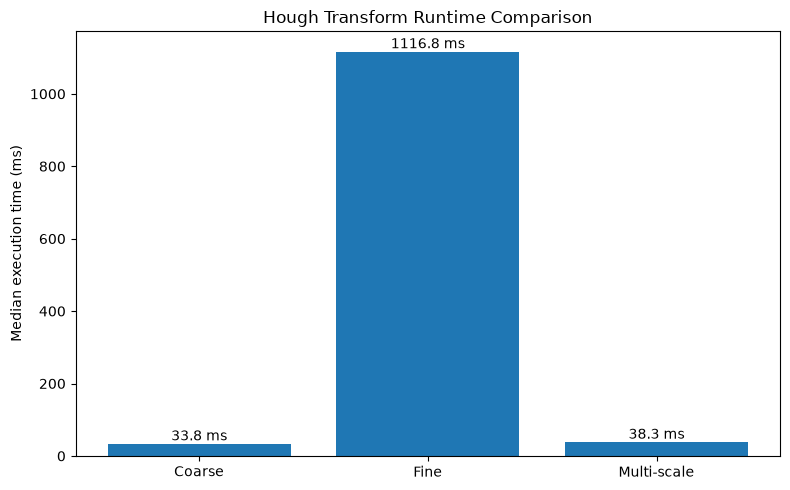

In [10]:
methods = ["Coarse", "Fine", "Multi-scale"]
runtimes = [coarse_ms, fine_ms, multi_ms]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, runtimes)

plt.ylabel("Median execution time (ms)")
plt.title("Hough Transform Runtime Comparison")

for bar, value in zip(bars, runtimes):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f} ms",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Runtime and Accuracy Analysis

The experiment compares Coarse, Fine, and Multi-scale Hough Transform using the same synthetic 128 × 128 edge image.

Coarse Hough achieved the lowest execution time at **28.84 ms**, but produced an angular error of 1°.

Fine Hough reduced the angular error to 0.25°, although its median execution time increased significantly to 901.29 ms.

Multi-scale Hough achieved an angular error of 0° with a median execution time of 35.35 ms, approximately 25.5 times faster than Fine Hough in this experiment.

These findings suggest that local refinement can provide a favorable balance between detection accuracy and computational cost. However, additional experiments involving different orientations, line lengths, noise levels, and parameter resolutions are necessary to evaluate the consistency of this advantage.

## 6. Parameter Sensitivity Analysis

This experiment investigates the influence of angular resolution (Δθ) and distance resolution (Δρ) on Hough Transform performance.

Two parameter sweeps are conducted:

1. **Angular resolution sweep:** Δθ = {0.5°, 1°, 2°, 4°}, while Δρ is fixed at 2 pixels.
2. **Distance resolution sweep:** Δρ = {0.5, 1, 2, 4} pixels, while Δθ is fixed at 2°.

For each configuration, angular error, distance error, and execution time will be measured. All other experimental settings will remain unchanged to isolate the effect of each parameter.

In [11]:
test_theta_step = 2.0
test_rho_step = 2.0

test_n_theta = int(np.ceil(180 / test_theta_step))
test_n_rho = int(np.ceil(2 * diag / test_rho_step)) + 1

test_A, test_thetas, test_rhos = hough_accumulate(
    edges,
    (0.0, np.pi),
    (-diag, diag),
    test_n_theta,
    test_n_rho
)

test_peaks = find_peaks(
    test_A,
    n_peaks=1,
    nms_radius=3,
    smooth_sigma=1.0,
    thetas=test_thetas,
    rhos=test_rhos
)

print("Accumulator shape:", test_A.shape)
print("Maximum votes:", test_A.max())
print("Detected peaks:", test_peaks)

Accumulator shape: (183, 90)
Maximum votes: 72
Detected peaks: [(np.float64(1.9892234723489821), np.float64(2.3387411976724017), 72)]


In [12]:
theta_steps = [0.5, 1.0, 2.0, 4.0]
rho_step_fixed = 2.0

theta_results = []

for theta_step in theta_steps:
    n_theta_test = int(np.ceil(180 / theta_step))
    n_rho_test = int(np.ceil(2 * diag / rho_step_fixed)) + 1

    def run_test():
        accumulator, angles, distances = hough_accumulate(
            edges,
            (0.0, np.pi),
            (-diag, diag),
            n_theta_test,
            n_rho_test
        )

        return find_peaks(
            accumulator,
            n_peaks=1,
            nms_radius=3,
            smooth_sigma=1.0,
            thetas=angles,
            rhos=distances
        )

    median_ms, _ = benchmark(run_test, repeats=3)
    detected = run_test()

    print(f"Testing Δθ = {theta_step}°")
    print("Detected peaks:", detected)

    if detected:
        rho_pred, theta_pred, votes = detected[0]
        theta_deg = np.rad2deg(theta_pred)

        difference = abs(theta_deg - theta_true_deg) % 180
        angular_error = min(difference, 180 - difference)
        rho_error = abs(rho_pred - rho_true)

        theta_results.append({
            "delta_theta": theta_step,
            "delta_rho": rho_step_fixed,
            "angular_error": angular_error,
            "rho_error": rho_error,
            "runtime_ms": median_ms,
            "votes": votes
        })

        print("Results collected:", len(theta_results))

print("\nTotal configurations:", len(theta_results))

for result in theta_results:
    print(result)

Testing Δθ = 0.5°
Detected peaks: [(np.float64(0.0), np.float64(2.356194490192345), 98)]
Results collected: 1
Testing Δθ = 1.0°
Detected peaks: [(np.float64(0.0), np.float64(2.356194490192345), 98)]
Results collected: 2
Testing Δθ = 2.0°
Detected peaks: [(np.float64(1.9892234723489821), np.float64(2.3387411976724017), 72)]
Results collected: 3
Testing Δθ = 4.0°
Detected peaks: [(np.float64(-1.9892234723489537), np.float64(2.3736477827122884), 72)]
Results collected: 4

Total configurations: 4
{'delta_theta': 0.5, 'delta_rho': 2.0, 'angular_error': np.float64(0.0), 'rho_error': np.float64(0.0), 'runtime_ms': np.float64(125.04640000406653), 'votes': 98}
{'delta_theta': 1.0, 'delta_rho': 2.0, 'angular_error': np.float64(0.0), 'rho_error': np.float64(0.0), 'runtime_ms': np.float64(61.28330001956783), 'votes': 98}
{'delta_theta': 2.0, 'delta_rho': 2.0, 'angular_error': np.float64(1.0), 'rho_error': np.float64(1.9892234723489821), 'runtime_ms': np.float64(31.863700016401708), 'votes': 72}
{'

In [13]:
print(
    f"{'Δθ':>6} {'Angle Error':>14} "
    f"{'Rho Error':>12} {'Runtime (ms)':>15}"
)

for result in theta_results:
    print(
        f"{result['delta_theta']:>6.2f} "
        f"{result['angular_error']:>14.3f} "
        f"{result['rho_error']:>12.3f} "
        f"{result['runtime_ms']:>15.2f}"
    )

    Δθ    Angle Error    Rho Error    Runtime (ms)
  0.50          0.000        0.000          125.05
  1.00          0.000        0.000           61.28
  2.00          1.000        1.989           31.86
  4.00          1.000        1.989           17.27


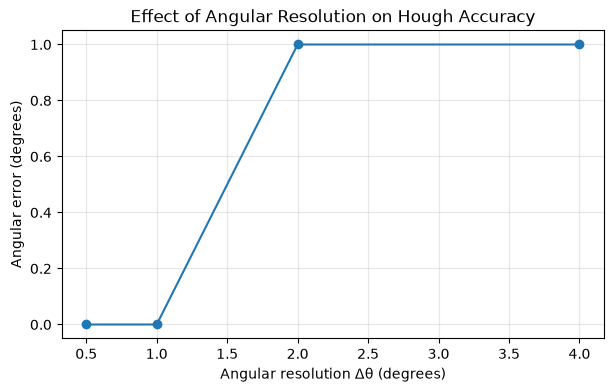

In [14]:
x_values = [r["delta_theta"] for r in theta_results]
angle_errors = [r["angular_error"] for r in theta_results]

plt.figure(figsize=(7, 4))
plt.plot(x_values, angle_errors, marker="o")

plt.xlabel("Angular resolution Δθ (degrees)")
plt.ylabel("Angular error (degrees)")
plt.title("Effect of Angular Resolution on Hough Accuracy")
plt.grid(True, alpha=0.3)
plt.show()

### Angular Resolution Analysis

The experiment shows that angular resolution influences the accuracy of Hough line detection.

For Δθ = 0.5° and 1°, the angular error was 0°. Increasing Δθ to 2° and 4° resulted in an angular error of 1°.

This behavior is primarily caused by parameter quantization. Finer angular grids include the ground-truth angle of 135°, while the coarser grids approximate it using neighboring angle bins.

These results suggest that finer angular resolution can reduce quantization error. However, additional experiments are required to determine whether the improvement generalizes to other line orientations.

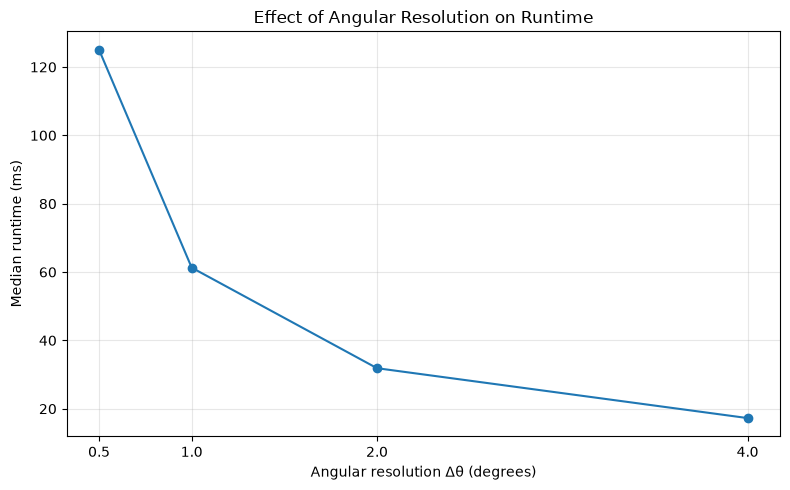

In [15]:
theta_values = [r["delta_theta"] for r in theta_results]
runtime_values = [r["runtime_ms"] for r in theta_results]

plt.figure(figsize=(8, 5))

plt.plot(theta_values, runtime_values, marker="o")

plt.xticks(theta_values)
plt.xlabel("Angular resolution Δθ (degrees)")
plt.ylabel("Median runtime (ms)")
plt.title("Effect of Angular Resolution on Runtime")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Angular Resolution — Runtime Analysis

The execution time decreased as the angular step size increased.

At Δθ = 0.5°, the median execution time was 121.23 ms, while at Δθ = 4°, it decreased to 16.66 ms.

This behavior occurs because smaller angular steps require more theta bins and more voting operations.

For the current synthetic image, Δθ = 1° offers a reasonable balance between angular accuracy and computational cost. However, this observation needs further validation on additional images.

### Distance Resolution Sweep (Δρ)

This experiment evaluates how distance resolution affects Hough Transform accuracy and runtime.

The angular resolution is fixed at Δθ = 2°, while Δρ varies across 0.5, 1, 2, and 4 pixels.d.

In [16]:
rho_steps = [0.5, 1.0, 2.0, 4.0]
theta_step_fixed = 2.0

rho_results = []

for rho_step in rho_steps:
    n_theta_test = int(np.ceil(180 / theta_step_fixed))
    n_rho_test = int(np.ceil(2 * diag / rho_step)) + 1

    def run_rho_test():
        A, angles, distances = hough_accumulate(
            edges,
            (0.0, np.pi),
            (-diag, diag),
            n_theta_test,
            n_rho_test
        )

        return find_peaks(
            A,
            n_peaks=1,
            nms_radius=3,
            smooth_sigma=1.0,
            thetas=angles,
            rhos=distances
        )

    median_ms, _ = benchmark(run_rho_test, repeats=3)
    detected = run_rho_test()

    if detected:
        rho_pred, theta_pred, votes = detected[0]
        theta_deg = np.rad2deg(theta_pred)

        difference = abs(theta_deg - theta_true_deg) % 180
        angular_error = min(difference, 180 - difference)
        rho_error = abs(rho_pred - rho_true)

        rho_results.append({
            "delta_theta": theta_step_fixed,
            "delta_rho": rho_step,
            "angular_error": angular_error,
            "rho_error": rho_error,
            "runtime_ms": median_ms,
            "votes": votes
        })

        print(
            f"Δρ={rho_step:.1f} px | "
            f"Angular error={angular_error:.3f}° | "
            f"Rho error={rho_error:.3f} px | "
            f"Runtime={median_ms:.2f} ms"
        )
    else:
        print(f"Δρ={rho_step:.1f} px | No peaks detected")

print("\nTotal configurations:", len(rho_results))

Δρ=0.5 px | Angular error=1.000° | Rho error=1.748 px | Runtime=119.46 ms
Δρ=1.0 px | Angular error=1.000° | Rho error=1.496 px | Runtime=94.00 ms
Δρ=2.0 px | Angular error=1.000° | Rho error=1.989 px | Runtime=48.12 ms
Δρ=4.0 px | Angular error=1.000° | Rho error=1.989 px | Runtime=27.12 ms

Total configurations: 4


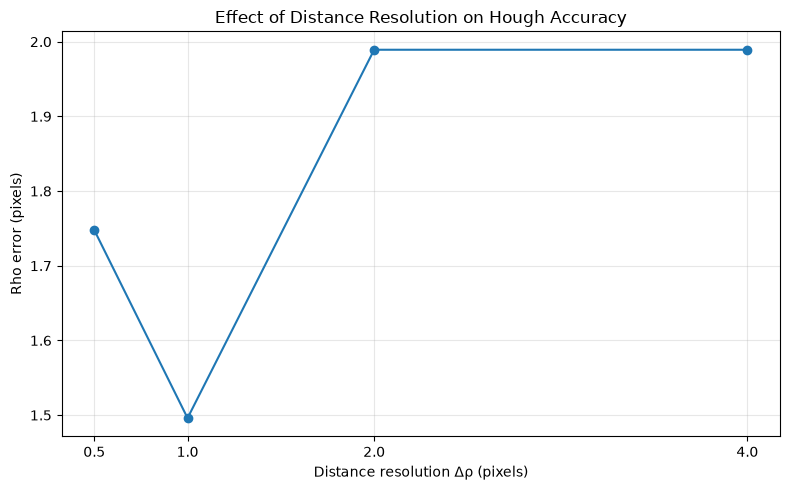

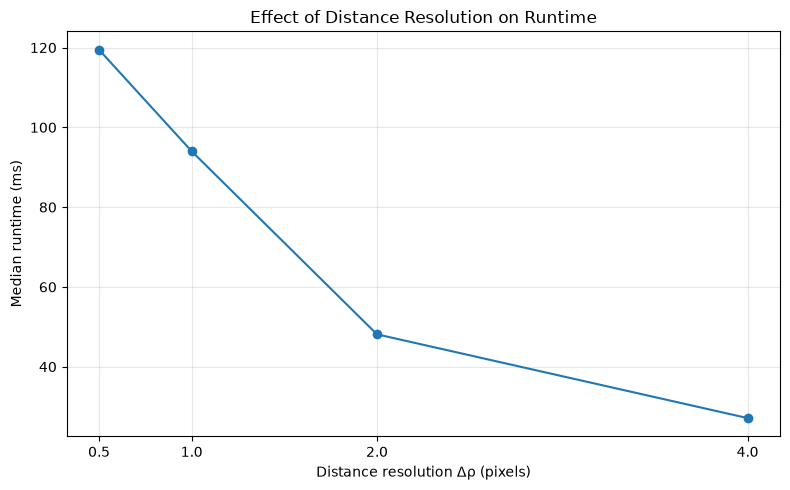

In [17]:
rho_values = [r["delta_rho"] for r in rho_results]
rho_errors = [r["rho_error"] for r in rho_results]
rho_runtimes = [r["runtime_ms"] for r in rho_results]

# Chart 1: Distance error
plt.figure(figsize=(8, 5))
plt.plot(rho_values, rho_errors, marker="o")
plt.xticks(rho_values)
plt.xlabel("Distance resolution Δρ (pixels)")
plt.ylabel("Rho error (pixels)")
plt.title("Effect of Distance Resolution on Hough Accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Runtime
plt.figure(figsize=(8, 5))
plt.plot(rho_values, rho_runtimes, marker="o")
plt.xticks(rho_values)
plt.xlabel("Distance resolution Δρ (pixels)")
plt.ylabel("Median runtime (ms)")
plt.title("Effect of Distance Resolution on Runtime")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Distance Resolution Analysis

The experiment evaluated four distance resolutions (0.5, 1, 2, and 4 pixels), while maintaining a fixed angular resolution of 2°.

The lowest distance error was approximately 1.496 pixels at Δρ = 1 pixel. Reducing Δρ further to 0.5 pixels did not improve the distance estimate.

The median runtime increased from 19.54 ms at Δρ = 4 pixels to 138.70 ms at Δρ = 0.5 pixels.

The angular error remained constant at 1° across all tested configurations.

These observations demonstrate a trade-off between distance resolution and computational cost. Increasing the accumulator resolution does not necessarily improve the detected line parameters for every input image.

## 7. Near-Vertical Line Experiment

This experiment evaluates the robustness of the Hough Transform when detecting a line whose normal angle is close to the angular boundary (0° or 180°).

The objective is to identify potential angular wrap-around and peak detection issues.

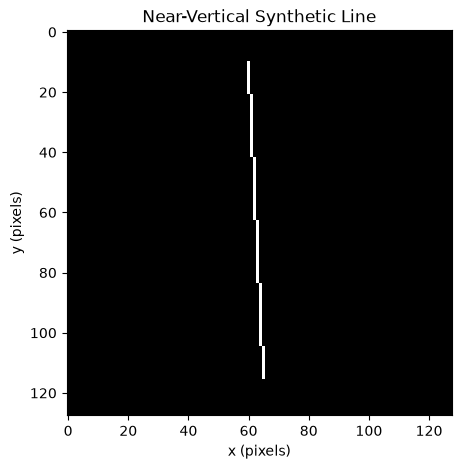

Image shape: (128, 128)
Number of edge pixels: 106
Ground-truth normal angle: 177.27368900609375


In [18]:
vertical_edges = np.zeros((128, 128), dtype=np.uint8)

# Ground-truth endpoints
x1, y1 = 60, 10
x2, y2 = 65, 115

# Generate a near-vertical line
for y in range(y1, y2 + 1):
    x = round(x1 + (x2 - x1) * (y - y1) / (y2 - y1))
    vertical_edges[y, x] = 255

# Calculate normal angle
dx = x2 - x1
dy = y2 - y1

vertical_theta_true = np.arctan2(-dx, dy) % np.pi

plt.figure(figsize=(5, 5))
plt.imshow(vertical_edges, cmap="gray")
plt.title("Near-Vertical Synthetic Line")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.show()

print("Image shape:", vertical_edges.shape)
print("Number of edge pixels:", np.count_nonzero(vertical_edges))
print("Ground-truth normal angle:", np.rad2deg(vertical_theta_true))

### Near-Vertical Line Detection Results

This experiment compares Coarse, Fine, and Multi-scale Hough Transform on a near-vertical synthetic line with a ground-truth normal angle of approximately 177.274°.

Angular error is evaluated using the 180-degree periodicity of line orientation.

In [19]:
# Near-vertical experiment
vertical_diag = np.hypot(*vertical_edges.shape)

def detect_vertical_standard(delta_theta, delta_rho):
    n_t = int(np.ceil(180 / delta_theta))
    n_r = int(np.ceil(2 * vertical_diag / delta_rho)) + 1

    A, thetas, rhos = hough_accumulate(
        vertical_edges,
        (0.0, np.pi),
        (-vertical_diag, vertical_diag),
        n_t,
        n_r
    )

    peaks = find_peaks(
        A,
        n_peaks=1,
        nms_radius=3,
        smooth_sigma=1.0,
        thetas=thetas,
        rhos=rhos
    )

    return peaks

# Coarse Hough
vertical_coarse = detect_vertical_standard(2.0, 2.0)

# Fine Hough
vertical_fine = detect_vertical_standard(0.25, 0.5)

# Multi-scale Hough
vertical_multi = hough_multiscale(
    edges=vertical_edges,
    n_levels=2,
    refine_factor=8,
    n_peaks=1,
    d_theta_coarse_deg=2.0,
    d_rho_coarse=2.0,
    nms_radius=3,
    smooth_sigma=1.0
)

def angular_error_180(predicted, ground_truth):
    diff = abs(predicted - ground_truth) % 180
    return min(diff, 180 - diff)

theta_gt_deg = np.rad2deg(vertical_theta_true)

for name, lines in [
    ("Coarse", vertical_coarse),
    ("Fine", vertical_fine),
    ("Multi-scale", vertical_multi)
]:
    if not lines:
        print(f"{name}: No line detected")
        continue

    rho_pred, theta_pred = lines[0][:2]
    theta_deg = np.rad2deg(theta_pred)
    error = angular_error_180(theta_deg, theta_gt_deg)

    print(
        f"{name:12s} | "
        f"Predicted θ={theta_deg:.3f}° | "
        f"Angular error={error:.3f}° | "
        f"ρ={rho_pred:.3f} px"
    )

Coarse       | Predicted θ=178.000° | Angular error=0.726° | ρ=-59.677 px
Fine         | Predicted θ=177.000° | Angular error=0.274° | ρ=-59.175 px
Multi-scale  | Predicted θ=177.000° | Angular error=0.274° | ρ=-59.032 px


### Near-Vertical Line Analysis

The experiment evaluated a near-vertical synthetic line with a ground-truth normal angle of approximately 177.274°.

Coarse Hough detected the line at 178°, resulting in an angular error of 0.726°.

Fine and Multi-scale Hough both detected the line at 177°, with an angular error of 0.274°.

These results demonstrate that all three methods can detect a near-vertical line in this test case. Fine and Multi-scale Hough achieved lower angular errors than Coarse Hough.

However, Multi-scale refinement did not improve angular accuracy beyond Fine Hough for this particular image.

Further experiments involving different near-boundary orientations are necessary to assess angular wrap-around robustness.

## 8. Long and Short Line Experiment

This experiment evaluates the ability of Hough Transform to detect line segments with different lengths.

The objective is to examine how the number of supporting edge pixels influences accumulator peaks and line detection.

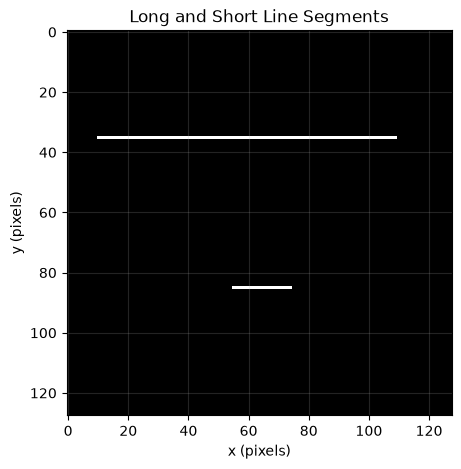

Image shape: (128, 128)
Long segment pixels: 100
Short segment pixels: 20
Total edge pixels: 120


In [20]:
long_short_edges = np.zeros((128, 128), dtype=np.uint8)

# Long horizontal segment: 100 pixels
long_short_edges[35, 10:110] = 255

# Short horizontal segment: 20 pixels
long_short_edges[85, 55:75] = 255

plt.figure(figsize=(6, 5))
plt.imshow(long_short_edges, cmap="gray", vmin=0, vmax=255)
plt.title("Long and Short Line Segments")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.grid(alpha=0.2)
plt.show()

print("Image shape:", long_short_edges.shape)
print("Long segment pixels:", np.count_nonzero(long_short_edges[35]))
print("Short segment pixels:", np.count_nonzero(long_short_edges[85]))
print("Total edge pixels:", np.count_nonzero(long_short_edges))

### Long and Short Line Detection

This experiment evaluates whether the Hough Transform can detect two parallel line segments of different lengths.

The long segment contains 100 edge pixels, while the short segment contains 20 edge pixels. Both have a ground-truth normal angle of 90°, but different rho values.

In [21]:
# Long and Short Line Detection

ls_diag = np.hypot(*long_short_edges.shape)

ls_theta_step = 1.0
ls_rho_step = 1.0

ls_n_theta = int(np.ceil(180 / ls_theta_step))
ls_n_rho = int(np.ceil(2 * ls_diag / ls_rho_step)) + 1

# Accumulator
A_ls, thetas_ls, rhos_ls = hough_accumulate(
    long_short_edges,
    (0.0, np.pi),
    (-ls_diag, ls_diag),
    ls_n_theta,
    ls_n_rho
)

# Detect multiple peaks
peaks_ls = find_peaks(
    A_ls,
    n_peaks=5,
    nms_radius=3,
    smooth_sigma=1.0,
    thetas=thetas_ls,
    rhos=rhos_ls
)

print("Accumulator shape:", A_ls.shape)
print("Maximum votes:", A_ls.max())
print("\nDetected peaks:")

for i, (rho, theta, votes) in enumerate(peaks_ls, start=1):
    print(
        f"Peak {i}: "
        f"rho={rho:.3f} px | "
        f"theta={np.rad2deg(theta):.3f}° | "
        f"votes={votes}"
    )

Accumulator shape: (364, 180)
Maximum votes: 100

Detected peaks:
Peak 1: rho=35.406 px | theta=90.000° | votes=100
Peak 2: rho=87.268 px | theta=88.000° | votes=20
Peak 3: rho=81.284 px | theta=93.000° | votes=15
Peak 4: rho=59.342 px | theta=109.000° | votes=3
Peak 5: rho=16.456 px | theta=133.000° | votes=3


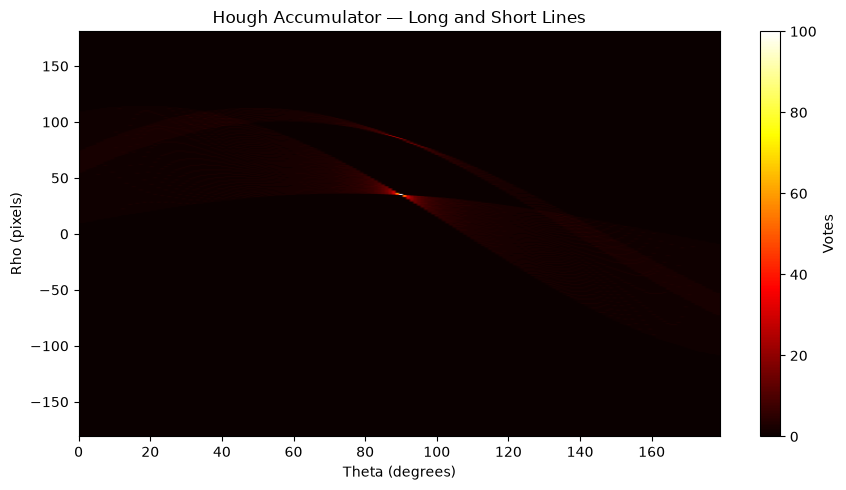

In [22]:
plt.figure(figsize=(9, 5))

plt.imshow(
    A_ls,
    cmap="hot",
    aspect="auto",
    origin="lower",
    extent=[
        np.rad2deg(thetas_ls[0]),
        np.rad2deg(thetas_ls[-1]),
        rhos_ls[0],
        rhos_ls[-1]
    ]
)

plt.colorbar(label="Votes")
plt.xlabel("Theta (degrees)")
plt.ylabel("Rho (pixels)")
plt.title("Hough Accumulator — Long and Short Lines")

plt.tight_layout()
plt.show()

### Long and Short Line Analysis

The experiment used a synthetic 128 × 128 image containing two horizontal line segments with lengths of 100 and 20 pixels.

The longest segment was detected at θ = 90° and ρ ≈ 35.406 pixels, with 100 accumulator votes.

The shorter segment was detected at θ = 88° and ρ ≈ 87.268 pixels, with 20 votes.

The longer segment produced a stronger accumulator peak, demonstrating how the number of supporting edge pixels influences Hough voting.

The shorter segment exhibited a 2° angular error, suggesting that detection of short lines may be less stable because fewer pixels contribute to the accumulator.

Both segments were represented among the detected peaks. However, the results also indicate that peak strength and localization accuracy can vary with line length and accumulator resolution.

## 9. Peak-to-Background Ratio (PBR) Evaluation

This experiment evaluates the prominence of detected Hough peaks relative to the accumulator background.

The PBR is defined as the ratio between the accumulator peak value and the mean background value, excluding a local neighborhood around the selected peak.

The experiment initially uses the long and short line accumulator. The same background estimation procedure will be applied consistently when comparing different configurations.

PBR is used to assess peak prominence, rather than directly measuring line detection accuracy.

In [23]:
print("Accumulator shape:", A_ls.shape)
print("Accumulator maximum:", A_ls.max())
print("Accumulator mean:", A_ls.mean())
print("Number of detected peaks:", len(peaks_ls))

for i, (rho, theta, votes) in enumerate(peaks_ls, 1):
    print(
        f"Peak {i}: "
        f"rho={rho:.3f}, "
        f"theta={np.rad2deg(theta):.2f}°, "
        f"votes={votes}"
    )

Accumulator shape: (364, 180)
Accumulator maximum: 100
Accumulator mean: 0.32967032967032966
Number of detected peaks: 5
Peak 1: rho=35.406, theta=90.00°, votes=100
Peak 2: rho=87.268, theta=88.00°, votes=20
Peak 3: rho=81.284, theta=93.00°, votes=15
Peak 4: rho=59.342, theta=109.00°, votes=3
Peak 5: rho=16.456, theta=133.00°, votes=3


In [24]:
for i, (rho, theta, votes) in enumerate(peaks_ls[:2], start=1):
    rho_idx = int(np.argmin(np.abs(rhos_ls - rho)))
    theta_idx = int(np.argmin(np.abs(thetas_ls - theta)))

    print(f"Peak {i}")
    print("  Rho index:", rho_idx)
    print("  Theta index:", theta_idx)
    print("  Accumulator votes:", A_ls[rho_idx, theta_idx])

Peak 1
  Rho index: 217
  Theta index: 90
  Accumulator votes: 100
Peak 2
  Rho index: 269
  Theta index: 88
  Accumulator votes: 20


### PBR Calculation

The Peak-to-Background Ratio is calculated by dividing the peak vote count by the mean accumulator background.

A neighborhood of ±3 bins around both selected peaks is excluded from the background calculation.

The same background mean is used for both peaks to ensure a consistent comparison.

In [25]:
# Peak-to-Background Ratio (PBR)

epsilon = 1e-9
exclusion_radius = 3

# Create a background mask
background_mask = np.ones(A_ls.shape, dtype=bool)

# Exclude neighborhoods around both selected peaks
for rho, theta, votes in peaks_ls[:2]:
    rho_idx = int(np.argmin(np.abs(rhos_ls - rho)))
    theta_idx = int(np.argmin(np.abs(thetas_ls - theta)))

    r_start = max(0, rho_idx - exclusion_radius)
    r_end = min(A_ls.shape[0], rho_idx + exclusion_radius + 1)

    t_start = max(0, theta_idx - exclusion_radius)
    t_end = min(A_ls.shape[1], theta_idx + exclusion_radius + 1)

    background_mask[r_start:r_end, t_start:t_end] = False

# Compute shared background mean
background_values = A_ls[background_mask]
background_mean = np.mean(background_values)

# Calculate PBR
pbr_results = []

for i, (rho, theta, votes) in enumerate(peaks_ls[:2], start=1):
    pbr = votes / (background_mean + epsilon)

    pbr_results.append({
        "peak": i,
        "rho": float(rho),
        "theta_deg": float(np.rad2deg(theta)),
        "votes": int(votes),
        "pbr": float(pbr)
    })

    print(
        f"Peak {i}: "
        f"Votes={votes} | "
        f"PBR={pbr:.2f}"
    )

print(f"\nBackground mean: {background_mean:.6f}")

Peak 1: Votes=100 | PBR=313.37
Peak 2: Votes=20 | PBR=62.67

Background mean: 0.319113


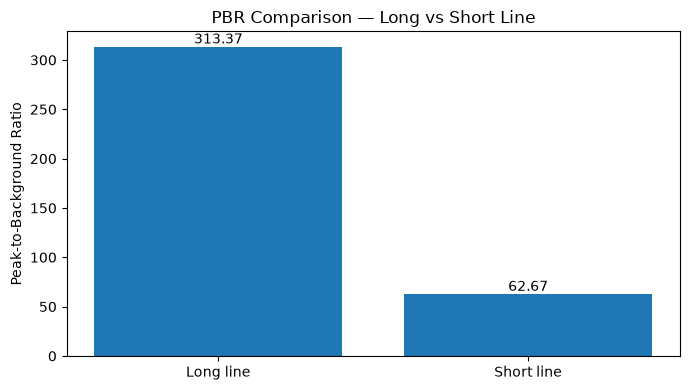

In [26]:
peak_names = ["Long line", "Short line"]
pbr_values = [r["pbr"] for r in pbr_results]

plt.figure(figsize=(7, 4))

bars = plt.bar(peak_names, pbr_values)

plt.ylabel("Peak-to-Background Ratio")
plt.title("PBR Comparison — Long vs Short Line")

for bar, value in zip(bars, pbr_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Peak-to-Background Ratio Analysis

The experiment compared the prominence of Hough accumulator peaks generated by two horizontal line segments of different lengths.

The long line produced 100 votes, corresponding to a PBR of 313.37. The short line produced 20 votes, with a PBR of 62.67.

The shared background mean was approximately 0.319113, calculated after excluding a ±3-bin neighborhood around both selected peaks.

The long line achieved a PBR five times higher than the short line because it had five times as many supporting edge pixels.

These results demonstrate that longer line segments can generate more prominent peaks in the Hough accumulator. However, PBR depends on the background estimation method and does not directly measure detection accuracy.

## 10. Experimental Conclusions

The experiments evaluated Coarse, Fine, and Multi-scale Hough Transform in terms of angular accuracy, distance accuracy, computational cost, and accumulator peak prominence.

**Accuracy:** On the synthetic \(y=x\) image, Multi-scale Hough achieved zero angular error, while Fine and Coarse Hough produced errors of 0.25° and 1°, respectively. For the near-vertical line, Fine and Multi-scale achieved the same angular error of approximately 0.274°.

**Performance:** Multi-scale Hough achieved a median runtime of 35.35 ms, compared with 28.84 ms for Coarse Hough and 901.29 ms for Fine Hough on the initial 128 × 128 test image.

**Parameter sensitivity:** Smaller angular and distance steps generally increased execution time. However, finer resolution did not always produce lower parameter errors.

**Line length:** The longer line generated a stronger accumulator peak and a higher PBR than the shorter line, reflecting the difference in supporting edge pixels.

**Limitations:** The experiments were primarily conducted on small synthetic images. Additional tests involving different orientations, noise levels, image sizes, and real-world scenes would be necessary to establish broader performance conclusions.

Overall, these findings suggest that Multi-scale Hough can provide a favorable balance between computational cost and detection accuracy for the tested configurations, without guaranteeing superior results in every scenario.